In [1]:
import os

print(os.listdir("/mnt/data"))

['HMDA_Project']


In [3]:
%pip install pandas pyarrow requests

Note: you may need to restart the kernel to use updated packages.


In [7]:
from pathlib import Path
import requests
import zipfile
import pandas as pd
import hashlib

YEAR = 2021

HMDA_URL = "https://files.ffiec.cfpb.gov/static-data/snapshot/2021/2021_public_lar_csv.zip"

DATASET_DIR = Path("/mnt/data/HMDA_Project")
TEMP_DIR = Path("/tmp/hmda_ingestion")
TEMP_DIR.mkdir(parents=True, exist_ok=True)

ZIP_PATH = TEMP_DIR / f"hmda_{YEAR}.zip"
OUTPUT_PATH = DATASET_DIR / f"hmda_{YEAR}.parquet"

print("Dataset directory:", DATASET_DIR)
print("Output:", OUTPUT_PATH)

Dataset directory: /mnt/data/HMDA_Project
Output: /mnt/data/HMDA_Project/hmda_2021.parquet


In [8]:
response = requests.get(HMDA_URL, stream=True, timeout=(30, 120))
response.raise_for_status()

sha256 = hashlib.sha256()
total_bytes = 0

with open(ZIP_PATH, "wb") as file:
    for block in response.iter_content(chunk_size=1024 * 1024):
        if block:
            file.write(block)
            sha256.update(block)
            total_bytes += len(block)

response.close()

print("Downloaded MB:", round(total_bytes / 1e6, 1))
print("SHA256:", sha256.hexdigest())
print("ZIP valid:", zipfile.is_zipfile(ZIP_PATH))

HTTPError: 403 Client Error: Forbidden for url: https://files.ffiec.cfpb.gov/static-data/snapshot/2021/2021_public_lar_csv.zip

In [9]:
import requests
import hashlib
import zipfile

headers = {
    "User-Agent": "Mozilla/5.0",
    "Accept": "*/*",
}

with requests.get(
    HMDA_URL,
    headers=headers,
    stream=True,
    timeout=(30, 120)
) as response:

    print("HTTP Status:", response.status_code)
    print("Final URL:", response.url)
    response.raise_for_status()

    sha256 = hashlib.sha256()
    total_bytes = 0

    with open(ZIP_PATH, "wb") as file:
        for block in response.iter_content(1024 * 1024):
            if block:
                file.write(block)
                sha256.update(block)
                total_bytes += len(block)

print("Downloaded MB:", round(total_bytes / 1e6, 1))
print("SHA256:", sha256.hexdigest())
print("ZIP valid:", zipfile.is_zipfile(ZIP_PATH))

HTTP Status: 200
Final URL: https://files.ffiec.cfpb.gov/static-data/snapshot/2021/2021_public_lar_csv.zip
Downloaded MB: 1517.9
SHA256: 20d61f6fc2e1e9c90b9199bb9075602cda718b4aa905807a6d8dec8433c7a3d3
ZIP valid: True


In [10]:
import zipfile
import pandas as pd

with zipfile.ZipFile(ZIP_PATH) as archive:
    csv_files = [
        name for name in archive.namelist()
        if name.lower().endswith(".csv")
    ]

    print("CSV files:", csv_files)

    with archive.open(csv_files[0]) as file:
        preview = pd.read_csv(file, nrows=5, dtype=str)

print("Number of columns:", len(preview.columns))
print("Columns:", preview.columns.tolist())

display(preview.head())

CSV files: ['2021_public_lar.csv']
Number of columns: 99
Columns: ['activity_year', 'lei', 'derived_msa_md', 'state_code', 'county_code', 'census_tract', 'conforming_loan_limit', 'derived_loan_product_type', 'derived_dwelling_category', 'derived_ethnicity', 'derived_race', 'derived_sex', 'action_taken', 'purchaser_type', 'preapproval', 'loan_type', 'loan_purpose', 'lien_status', 'reverse_mortgage', 'open_end_line_of_credit', 'business_or_commercial_purpose', 'loan_amount', 'combined_loan_to_value_ratio', 'interest_rate', 'rate_spread', 'hoepa_status', 'total_loan_costs', 'total_points_and_fees', 'origination_charges', 'discount_points', 'lender_credits', 'loan_term', 'prepayment_penalty_term', 'intro_rate_period', 'negative_amortization', 'interest_only_payment', 'balloon_payment', 'other_nonamortizing_features', 'property_value', 'construction_method', 'occupancy_type', 'manufactured_home_secured_property_type', 'manufactured_home_land_property_interest', 'total_units', 'multifamily_a

,activity_year,lei,derived_msa_md,state_code,county_code,census_tract,conforming_loan_limit,derived_loan_product_type,derived_dwelling_category,derived_ethnicity,...,denial_reason_2,denial_reason_3,denial_reason_4,tract_population,tract_minority_population_percent,ffiec_msa_md_median_family_income,tract_to_msa_income_percentage,tract_owner_occupied_units,tract_one_to_four_family_homes,tract_median_age_of_housing_units
0,2021,5493006LH4LKHY2EIN26,15380,NY,36029,36029007304,C,Conventional:First Lien,Single Family (1-4 Units):Site-Built,Not Hispanic or Latino,...,NaN,NaN,NaN,5455,2.50999999999999979,78900,152.0,1943,2018,31
1,2021,5493006LH4LKHY2EIN26,40380,NY,36051,36051031200,C,Conventional:First Lien,Single Family (1-4 Units):Site-Built,Not Hispanic or Latino,...,NaN,NaN,NaN,3763,2.02000000000000002,82900,86.0,1225,1704,67
2,2021,5493006LH4LKHY2EIN26,15380,NY,36029,36029001700,C,Conventional:First Lien,Single Family (1-4 Units):Site-Built,Not Hispanic or Latino,...,NaN,NaN,NaN,1665,40,78900,46.0,312,837,76
3,2021,5493006LH4LKHY2EIN26,15380,NY,36029,36029004800,C,Conventional:First Lien,Single Family (1-4 Units):Site-Built,Not Hispanic or Latino,...,NaN,NaN,NaN,4212,18.0399999999999991,78900,137.0,1097,1744,76
4,2021,5493006LH4LKHY2EIN26,21300,NY,36015,36015010700,C,Conventional:First Lien,Single Family (1-4 Units):Site-Built,Not Hispanic or Latino,...,NaN,NaN,NaN,7830,11.1400000000000006,67600,151.0,2567,2892,45


In [11]:
import pandas as pd
import numpy as np
import zipfile
from pathlib import Path

YEAR = 2021
SAMPLE_SIZE = 25_000
CHUNK_SIZE = 100_000

OUTPUT_PATH = Path(f"/mnt/data/HMDA_Project/hmda_{YEAR}.parquet")

rng = np.random.default_rng(42)

required = [
    "action_taken",
    "loan_purpose",
    "lien_status",
    "occupancy_type",
    "construction_method",
    "total_units",
]

# Columns to retain for modeling and fairness analysis
keep_columns = [
    "activity_year",
    "lei",
    "state_code",
    "county_code",
    "census_tract",
    "action_taken",
    "loan_type",
    "loan_purpose",
    "lien_status",
    "occupancy_type",
    "construction_method",
    "total_units",
    "loan_amount",
    "income",
    "debt_to_income_ratio",
    "combined_loan_to_value_ratio",
    "loan_term",
    "property_value",
    "applicant_age",
    "applicant_sex",
    "applicant_race_1",
    "applicant_ethnicity_1",
    "derived_race",
    "derived_ethnicity",
    "derived_sex",
    "denial_reason_1",
]

available_columns = [
    col for col in keep_columns if col in preview.columns
]

missing = set(required) - set(preview.columns)
if missing:
    raise ValueError(f"Missing required columns: {missing}")

sample = None
processed_total = 0
eligible_total = 0

with zipfile.ZipFile(ZIP_PATH) as archive:
    with archive.open(csv_files[0]) as file:

        for chunk in pd.read_csv(
            file,
            chunksize=CHUNK_SIZE,
            dtype=str,
            usecols=available_columns,
        ):
            processed_total += len(chunk)

            # Filter to comparable mortgage applications
            filtered = chunk[
                chunk["action_taken"].isin(["1", "2", "3"])
                & chunk["loan_purpose"].eq("1")
                & chunk["lien_status"].eq("1")
                & chunk["occupancy_type"].eq("1")
                & chunk["construction_method"].eq("1")
                & chunk["total_units"].isin(["1", "2", "3", "4"])
            ].copy()

            n = len(filtered)
            eligible_total += n

            if n == 0:
                continue

            # Fixed-seed random sample across the full dataset
            filtered["_priority"] = rng.random(n)

            if sample is None:
                sample = filtered
            else:
                sample = pd.concat(
                    [sample, filtered],
                    ignore_index=True
                )

            if len(sample) > SAMPLE_SIZE:
                sample = sample.nsmallest(
                    SAMPLE_SIZE,
                    "_priority"
                ).copy()

            if processed_total % 1_000_000 == 0:
                print(
                    f"Processed {processed_total:,} rows; "
                    f"eligible {eligible_total:,}"
                )

if sample is None or sample.empty:
    raise ValueError("No eligible mortgage applications found")

sample = sample.drop(columns=["_priority"])
sample["source_year"] = YEAR

# 1 = originated, 2 = approved but not accepted
# 3 = denied
sample["approved"] = sample["action_taken"].isin(
    ["1", "2"]
).astype(int)

sample.to_parquet(
    OUTPUT_PATH,
    index=False,
    compression="snappy"
)

print("\nSUCCESS!")
print("Total records scanned:", f"{processed_total:,}")
print("Eligible applications:", f"{eligible_total:,}")
print("Sample size:", len(sample))
print("Approval rate:", round(sample["approved"].mean() * 100, 2), "%")
print("Parquet saved:", OUTPUT_PATH)
print("File size:", round(OUTPUT_PATH.stat().st_size / 1e6, 2), "MB")

Processed 1,000,000 rows; eligible 205,017
Processed 2,000,000 rows; eligible 470,136
Processed 3,000,000 rows; eligible 682,732
Processed 4,000,000 rows; eligible 934,515
Processed 5,000,000 rows; eligible 1,093,389
Processed 6,000,000 rows; eligible 1,334,999
Processed 7,000,000 rows; eligible 1,588,437
Processed 8,000,000 rows; eligible 1,813,750
Processed 9,000,000 rows; eligible 1,964,100
Processed 10,000,000 rows; eligible 2,037,536
Processed 11,000,000 rows; eligible 2,217,647
Processed 12,000,000 rows; eligible 2,426,776
Processed 13,000,000 rows; eligible 2,594,852
Processed 14,000,000 rows; eligible 2,820,005
Processed 15,000,000 rows; eligible 2,936,279
Processed 16,000,000 rows; eligible 3,089,286
Processed 17,000,000 rows; eligible 3,268,247
Processed 18,000,000 rows; eligible 3,390,183
Processed 19,000,000 rows; eligible 3,499,306
Processed 20,000,000 rows; eligible 3,706,905
Processed 21,000,000 rows; eligible 3,799,809
Processed 22,000,000 rows; eligible 3,999,751
Proce

In [12]:
df = pd.read_parquet(
    "/mnt/data/HMDA_Project/hmda_2021.parquet"
)

print("Shape:", df.shape)
print("\nApproval outcomes:")
print(df["approved"].value_counts())

print("\nMissing income:")
print(df["income"].isna().mean())

display(df.head())

Shape: (25000, 28)

Approval outcomes:
approved
1    22907
0     2093
Name: count, dtype: int64

Missing income:
0.00844


,activity_year,lei,state_code,county_code,census_tract,derived_ethnicity,derived_race,derived_sex,action_taken,loan_type,...,total_units,income,debt_to_income_ratio,applicant_ethnicity_1,applicant_race_1,applicant_sex,applicant_age,denial_reason_1,source_year,approved
0,2021,549300MCIFZSDHUT8X63,NC,37119,37119005620,Not Hispanic or Latino,Black or African American,Male,1,1,...,1,75,20%-<30%,2,3,1,25-34,10,2021,1
1,2021,549300NFPC3Y4W3Y7R87,NC,37183,37183054113,Not Hispanic or Latino,Black or African American,Male,1,2,...,1,61,50%-60%,2,3,1,25-34,10,2021,1
2,2021,549300CTZWA68906Q837,OR,41051,41051009400,Not Hispanic or Latino,Black or African American,Male,1,3,...,1,54,>60%,2,3,1,65-74,10,2021,1
3,2021,549300MFY0P4D234OB91,FL,12057,12057013311,Not Hispanic or Latino,White,Joint,1,1,...,1,71,30%-<36%,2,5,1,35-44,10,2021,1
4,2021,EQTWLK1G7ODGC2MGLV11,GA,13245,13245010204,Not Hispanic or Latino,White,Male,3,3,...,1,51,44,2,5,1,25-34,1,2021,0


In [13]:
import requests
import pandas as pd
import numpy as np
import zipfile
import hashlib
import json
import gc
from pathlib import Path

# Configuration
YEARS = [2022, 2023, 2024, 2025]
SAMPLE_SIZE = 25_000
CHUNK_SIZE = 100_000
SEED = 42

DATASET_DIR = Path("/mnt/data/HMDA_Project")
TEMP_DIR = Path("/tmp/hmda_ingestion")

DATASET_DIR.mkdir(parents=True, exist_ok=True)
TEMP_DIR.mkdir(parents=True, exist_ok=True)

# Verify these URLs against the official HMDA Snapshot pages.
# The 2021 URL worked, but the other URLs are not yet verified.
URLS = {
    year: (
        f"https://files.ffiec.cfpb.gov/static-data/"
        f"snapshot/{year}/{year}_public_lar_csv.zip"
    )
    for year in YEARS
}

KEEP_COLUMNS = [
    "activity_year",
    "lei",
    "state_code",
    "county_code",
    "census_tract",
    "action_taken",
    "loan_type",
    "loan_purpose",
    "lien_status",
    "occupancy_type",
    "construction_method",
    "total_units",
    "loan_amount",
    "income",
    "debt_to_income_ratio",
    "combined_loan_to_value_ratio",
    "loan_term",
    "property_value",
    "applicant_age",
    "applicant_sex",
    "applicant_race_1",
    "applicant_ethnicity_1",
    "derived_race",
    "derived_ethnicity",
    "derived_sex",
    "denial_reason_1",
]

REQUIRED = [
    "action_taken",
    "loan_purpose",
    "lien_status",
    "occupancy_type",
    "construction_method",
    "total_units",
]

HEADERS = {
    "User-Agent": "Mozilla/5.0",
    "Accept": "*/*",
}

manifest = {}

for year in YEARS:
    print(f"\n{'='*50}")
    print(f"PROCESSING HMDA {year}")
    print(f"{'='*50}")

    url = URLS[year]
    zip_path = TEMP_DIR / f"hmda_{year}.zip"
    output_path = DATASET_DIR / f"hmda_{year}.parquet"

    if output_path.exists():
        print(f"Already exists: {output_path}")
        print("Skipping this year.")
        continue

    # 1. Download ZIP
    print("Downloading:", url)

    sha256 = hashlib.sha256()
    total_bytes = 0

    with requests.get(
        url,
        headers=HEADERS,
        stream=True,
        timeout=(30, 120)
    ) as response:

        response.raise_for_status()

        with open(zip_path, "wb") as f:
            for block in response.iter_content(1024 * 1024):
                if block:
                    f.write(block)
                    sha256.update(block)
                    total_bytes += len(block)

    if not zipfile.is_zipfile(zip_path):
        raise ValueError(f"Invalid ZIP for {year}")

    print(f"Downloaded: {total_bytes / 1e6:.1f} MB")

    # 2. Process CSV in chunks
    rng = np.random.default_rng(SEED)
    sample = None
    processed_total = 0
    eligible_total = 0

    with zipfile.ZipFile(zip_path) as archive:
        csv_files = [
            name for name in archive.namelist()
            if name.lower().endswith(".csv")
        ]

        if len(csv_files) != 1:
            raise ValueError(
                f"Expected one CSV for {year}, found {csv_files}"
            )

        with archive.open(csv_files[0]) as file:
            for chunk in pd.read_csv(
                file,
                chunksize=CHUNK_SIZE,
                dtype=str,
                usecols=lambda c: c in KEEP_COLUMNS,
            ):
                processed_total += len(chunk)

                missing = set(REQUIRED) - set(chunk.columns)
                if missing:
                    raise ValueError(
                        f"{year}: Missing columns {missing}"
                    )

                filtered = chunk[
                    chunk["action_taken"].isin(["1", "2", "3"])
                    & chunk["loan_purpose"].eq("1")
                    & chunk["lien_status"].eq("1")
                    & chunk["occupancy_type"].eq("1")
                    & chunk["construction_method"].eq("1")
                    & chunk["total_units"].isin(["1", "2", "3", "4"])
                ].copy()

                n = len(filtered)
                eligible_total += n

                if n == 0:
                    continue

                filtered["_priority"] = rng.random(n)

                if sample is None:
                    sample = filtered
                else:
                    sample = pd.concat(
                        [sample, filtered],
                        ignore_index=True
                    )

                if len(sample) > SAMPLE_SIZE:
                    sample = sample.nsmallest(
                        SAMPLE_SIZE, "_priority"
                    ).copy()

                if processed_total % 1_000_000 == 0:
                    print(
                        f"Scanned {processed_total:,} rows; "
                        f"eligible {eligible_total:,}"
                    )

    if sample is None or sample.empty:
        raise ValueError(f"No eligible records for {year}")

    # 3. Prepare final data
    sample = sample.drop(columns=["_priority"])
    sample["source_year"] = year
    sample["approved"] = (
        sample["action_taken"].isin(["1", "2"])
    ).astype(int)

    # 4. Save Parquet
    sample.to_parquet(
        output_path,
        index=False,
        compression="snappy"
    )

    approval_rate = sample["approved"].mean()

    manifest[str(year)] = {
        "source_url": url,
        "source_sha256": sha256.hexdigest(),
        "rows_scanned": processed_total,
        "eligible_rows": eligible_total,
        "sample_rows": len(sample),
        "sample_seed": SEED,
        "approval_rate": float(approval_rate),
        "output_file": output_path.name,
    }

    print(f"\nSUCCESS: {year}")
    print("Rows scanned:", f"{processed_total:,}")
    print("Eligible:", f"{eligible_total:,}")
    print("Saved rows:", len(sample))
    print("Approval rate:", f"{approval_rate:.2%}")
    print("Output:", output_path)

    # Remove temporary ZIP to conserve disk space
    zip_path.unlink()
    del sample
    gc.collect()

# 5. Save metadata
manifest_path = DATASET_DIR / "ingestion_manifest_2022_2025.json"

with open(manifest_path, "w") as f:
    json.dump(manifest, f, indent=2)

print("\nALL AVAILABLE YEARS PROCESSED")
print("Manifest:", manifest_path)


PROCESSING HMDA 2022
Downloading: https://files.ffiec.cfpb.gov/static-data/snapshot/2022/2022_public_lar_csv.zip
Downloaded: 877.7 MB
Scanned 1,000,000 rows; eligible 332,280
Scanned 2,000,000 rows; eligible 642,065
Scanned 3,000,000 rows; eligible 1,008,848
Scanned 4,000,000 rows; eligible 1,276,996
Scanned 5,000,000 rows; eligible 1,442,311
Scanned 6,000,000 rows; eligible 1,712,081
Scanned 7,000,000 rows; eligible 1,888,462
Scanned 8,000,000 rows; eligible 2,100,580
Scanned 9,000,000 rows; eligible 2,320,285
Scanned 10,000,000 rows; eligible 2,522,080
Scanned 11,000,000 rows; eligible 2,914,215
Scanned 12,000,000 rows; eligible 3,139,753
Scanned 13,000,000 rows; eligible 3,362,999
Scanned 14,000,000 rows; eligible 3,593,764
Scanned 15,000,000 rows; eligible 3,825,909
Scanned 16,000,000 rows; eligible 4,047,471

SUCCESS: 2022
Rows scanned: 16,080,210
Eligible: 4,052,621
Saved rows: 25000
Approval rate: 90.64%
Output: /mnt/data/HMDA_Project/hmda_2022.parquet

PROCESSING HMDA 2023
Dow

In [14]:
from pathlib import Path
import pandas as pd

dataset_dir = Path("/mnt/data/HMDA_Project")

results = []

for year in range(2021, 2026):
    path = dataset_dir / f"hmda_{year}.parquet"

    if path.exists():
        df = pd.read_parquet(path)

        results.append({
            "Year": year,
            "Applications": len(df),
            "Approved": int(df["approved"].sum()),
            "Denied": int((df["approved"] == 0).sum()),
            "Approval Rate": f"{df['approved'].mean():.2%}",
            "Size (MB)": round(path.stat().st_size / 1e6, 2)
        })

summary = pd.DataFrame(results)
display(summary)

,Year,Applications,Approved,Denied,Approval Rate,Size (MB)
0,2021,25000,22907,2093,91.63%,0.60
1,2022,25000,22661,2339,90.64%,0.63
2,2023,25000,22647,2353,90.59%,0.63
3,2024,25000,22715,2285,90.86%,0.63
4,2025,25000,22821,2179,91.28%,0.63


In [15]:
import sklearn
import joblib

print("Scikit-learn:", sklearn.__version__)
print("Joblib is available!")

Scikit-learn: 1.7.2
Joblib is available!


In [16]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path("/mnt/data/HMDA_Project")

# Training data: 2021–2023
train = pd.concat([
    pd.read_parquet(DATA_DIR / f"hmda_{year}.parquet")
    for year in [2021, 2022, 2023]
], ignore_index=True)

# Validation data: 2024
val = pd.read_parquet(DATA_DIR / "hmda_2024.parquet")

# Test data: 2025
test = pd.read_parquet(DATA_DIR / "hmda_2025.parquet")

print("Training:", train.shape)
print("Validation:", val.shape)
print("Testing:", test.shape)

print("\nApproval rates:")
print("Train:", f"{train['approved'].mean():.2%}")
print("Validation:", f"{val['approved'].mean():.2%}")
print("Test:", f"{test['approved'].mean():.2%}")

Training: (75000, 28)
Validation: (25000, 28)
Testing: (25000, 28)

Approval rates:
Train: 90.95%
Validation: 90.86%
Test: 91.28%


In [17]:
import numpy as np

NUMERIC_FEATURES = [
    "loan_amount",
    "income",
    "combined_loan_to_value_ratio",
]

CATEGORICAL_FEATURES = [
    "debt_to_income_ratio",
    "loan_type",
    "loan_term",
]

FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

def prepare_features(df):
    X = df[FEATURES].copy()

    for col in NUMERIC_FEATURES:
        X[col] = pd.to_numeric(X[col], errors="coerce")

    for col in CATEGORICAL_FEATURES:
        X[col] = X[col].fillna("Missing").astype(str)

    return X

X_train = prepare_features(train)
X_val = prepare_features(val)
X_test = prepare_features(test)

y_train = train["approved"].astype(int)
y_val = val["approved"].astype(int)
y_test = test["approved"].astype(int)

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Testing features:", X_test.shape)

display(X_train.head())

Training features: (75000, 6)
Validation features: (25000, 6)
Testing features: (25000, 6)


,loan_amount,income,combined_loan_to_value_ratio,debt_to_income_ratio,loan_type,loan_term
0,245000,75.0,80.0,20%-<30%,1,360
1,265000,61.0,96.5,50%-60%,2,360
2,385000,54.0,100.0,>60%,3,360
3,255000,71.0,97.0,30%-<36%,1,360
4,155000,51.0,100.0,44,3,360


In [19]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

# Handle numeric features
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Handle categorical features
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, NUMERIC_FEATURES),
    ("categorical", categorical_transformer, CATEGORICAL_FEATURES)
])

# Build the complete model
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train using 2021–2023 only
model.fit(X_train, y_train)

print("Model trained successfully!")
print("Training records:", len(X_train))
print("Model:", model.named_steps["classifier"])


Model trained successfully!
Training records: 75000
Model: LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42)


In [20]:

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report
)

def evaluate_model(model, X, y, year):
    probabilities = model.predict_proba(X)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    print(f"\n{'=' * 40}")
    print(f"HMDA {year} MODEL EVALUATION")
    print(f"{'=' * 40}")

    print("ROC-AUC:", round(roc_auc_score(y, probabilities), 4))
    print("Accuracy:", round(accuracy_score(y, predictions), 4))
    print("Balanced accuracy:", round(
        balanced_accuracy_score(y, predictions), 4
    ))

    print("Approval precision:", round(
        precision_score(y, predictions), 4
    ))
    print("Approval recall:", round(
        recall_score(y, predictions), 4
    ))

    print("Denial recall:", round(
        recall_score(y, predictions, pos_label=0), 4
    ))

    print("\nConfusion matrix:")
    print(confusion_matrix(y, predictions))

    print("\nClassification report:")
    print(classification_report(
        y,
        predictions,
        target_names=["Denied", "Approved"],
        zero_division=0
    ))

    return {
        "roc_auc": float(roc_auc_score(y, probabilities)),
        "accuracy": float(accuracy_score(y, predictions)),
        "balanced_accuracy": float(
            balanced_accuracy_score(y, predictions)
        ),
        "denial_recall": float(
            recall_score(y, predictions, pos_label=0)
        )
    }

# Validate using 2024
val_metrics = evaluate_model(model, X_val, y_val, 2024)

# Final held-out evaluation using 2025
test_metrics = evaluate_model(model, X_test, y_test, 2025)



HMDA 2024 MODEL EVALUATION
ROC-AUC: 0.7397
Accuracy: 0.8042
Balanced accuracy: 0.6899
Approval precision: 0.9483
Approval recall: 0.8297
Denial recall: 0.5501

Confusion matrix:
[[ 1257  1028]
 [ 3868 18847]]

Classification report:
              precision    recall  f1-score   support

      Denied       0.25      0.55      0.34      2285
    Approved       0.95      0.83      0.89     22715

    accuracy                           0.80     25000
   macro avg       0.60      0.69      0.61     25000
weighted avg       0.88      0.80      0.84     25000


HMDA 2025 MODEL EVALUATION
ROC-AUC: 0.7376
Accuracy: 0.8016
Balanced accuracy: 0.6809
Approval precision: 0.949
Approval recall: 0.8271
Denial recall: 0.5346

Confusion matrix:
[[ 1165  1014]
 [ 3945 18876]]

Classification report:
              precision    recall  f1-score   support

      Denied       0.23      0.53      0.32      2179
    Approved       0.95      0.83      0.88     22821

    accuracy                           0.8

In [21]:
from sklearn.metrics import (
    balanced_accuracy_score,
    precision_score,
    recall_score
)
import pandas as pd
import numpy as np

val_probs = model.predict_proba(X_val)[:, 1]

results = []

for threshold in np.arange(0.2, 0.81, 0.05):
    preds = (val_probs >= threshold).astype(int)

    results.append({
        "threshold": round(float(threshold), 2),
        "balanced_accuracy": balanced_accuracy_score(y_val, preds),
        "denial_recall": recall_score(
            y_val, preds, pos_label=0
        ),
        "denial_precision": precision_score(
            y_val, preds, pos_label=0, zero_division=0
        ),
        "accuracy": (preds == y_val).mean()
    })

threshold_df = pd.DataFrame(results)
display(threshold_df.round(3))

best = threshold_df.loc[
    threshold_df["balanced_accuracy"].idxmax()
]

print("\nBest validation threshold:", best["threshold"])
print("Balanced accuracy:", round(best["balanced_accuracy"], 4))
print("Denial recall:", round(best["denial_recall"], 4))

,threshold,balanced_accuracy,denial_recall,denial_precision,accuracy
0,0.20,0.632,0.276,0.694,0.923
1,0.25,0.635,0.284,0.665,0.921
2,0.30,0.645,0.367,0.323,0.872
3,0.35,0.668,0.420,0.338,0.872
4,0.40,0.683,0.481,0.296,0.848
5,0.45,0.688,0.498,0.289,0.842
6,0.50,0.690,0.550,0.245,0.804
7,0.55,0.681,0.640,0.188,0.715
8,0.60,0.655,0.738,0.148,0.588
9,0.65,0.610,0.839,0.120,0.423



Best validation threshold: 0.5
Balanced accuracy: 0.6899
Denial recall: 0.5501


In [22]:
import joblib
import json
from pathlib import Path

MODEL_DIR = Path("/mnt/data/HMDA_Project/models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save trained model, including preprocessing
joblib.dump(
    model,
    MODEL_DIR / "mortgage_approval_model.joblib"
)

# Save evaluation metrics and configuration
results = {
    "model": "Logistic Regression",
    "training_years": [2021, 2022, 2023],
    "validation_year": 2024,
    "test_year": 2025,
    "features": FEATURES,
    "class_weight": "balanced",
    "threshold": 0.50,
    "validation_metrics": val_metrics,
    "test_metrics": test_metrics
}

with open(MODEL_DIR / "model_metrics.json", "w") as f:
    json.dump(results, f, indent=2)

print("Model saved successfully!")
print("Metrics saved successfully!")

Model saved successfully!
Metrics saved successfully!


In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Get feature names after preprocessing
feature_names = model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Get trained logistic regression coefficients
coefficients = model.named_steps[
    "classifier"
].coef_[0]

feature_importance = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients,
})

feature_importance["absolute_coefficient"] = (
    feature_importance["coefficient"].abs()
)

feature_importance = feature_importance.sort_values(
    "absolute_coefficient",
    ascending=False
)

display(feature_importance.head(15))

,feature,coefficient,absolute_coefficient
21,categorical__debt_to_income_ratio_>60%,-3.842035,3.842035
36,categorical__loan_term_144,-1.957369,1.957369
23,categorical__debt_to_income_ratio_Missing,-1.724784,1.724784
30,categorical__loan_term_108,-1.541745,1.541745
88,categorical__loan_term_30,1.486413,1.486413
142,categorical__loan_term_373,-1.440935,1.440935
158,categorical__loan_term_62,1.367519,1.367519
40,categorical__loan_term_160,-1.282153,1.282153
149,categorical__loan_term_419,-1.281384,1.281384
75,categorical__loan_term_263,-1.278451,1.278451


In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Get feature names after preprocessing
feature_names = model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Get trained logistic regression coefficients
coefficients = model.named_steps[
    "classifier"
].coef_[0]

feature_importance = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients,
})

feature_importance["absolute_coefficient"] = (
    feature_importance["coefficient"].abs()
)

feature_importance = feature_importance.sort_values(
    "absolute_coefficient",
    ascending=False
)

display(feature_importance.head(15))

,feature,coefficient,absolute_coefficient
21,categorical__debt_to_income_ratio_>60%,-3.842035,3.842035
36,categorical__loan_term_144,-1.957369,1.957369
23,categorical__debt_to_income_ratio_Missing,-1.724784,1.724784
30,categorical__loan_term_108,-1.541745,1.541745
88,categorical__loan_term_30,1.486413,1.486413
142,categorical__loan_term_373,-1.440935,1.440935
158,categorical__loan_term_62,1.367519,1.367519
40,categorical__loan_term_160,-1.282153,1.282153
149,categorical__loan_term_419,-1.281384,1.281384
75,categorical__loan_term_263,-1.278451,1.278451


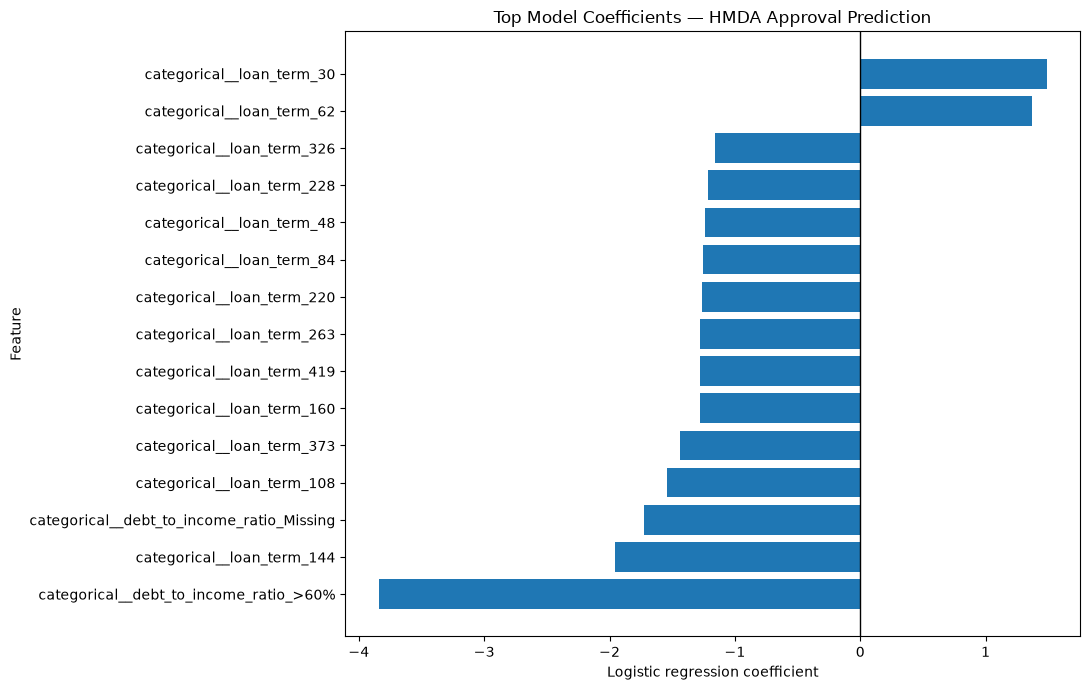

In [25]:
top_features = feature_importance.head(15).sort_values(
    "coefficient"
)

plt.figure(figsize=(11, 7))

plt.barh(
    top_features["feature"],
    top_features["coefficient"]
)

plt.axvline(0, color="black", linewidth=1)

plt.xlabel("Logistic regression coefficient")
plt.ylabel("Feature")
plt.title("Top Model Coefficients — HMDA Approval Prediction")
plt.tight_layout()
plt.show()

In [26]:
race_summary = (
    test.groupby("derived_race", dropna=False)
    .agg(
        applications=("approved", "size"),
        approved=("approved", "sum"),
        approval_rate=("approved", "mean")
    )
    .reset_index()
    .sort_values("applications", ascending=False)
)

race_summary["approval_rate"] = (
    race_summary["approval_rate"] * 100
)

display(race_summary.round(2))


,derived_race,applications,approved,approval_rate
8,White,16800,15562,92.63
7,Race Not Available,3347,3002,89.69
3,Black or African American,2072,1740,83.98
2,Asian,1773,1618,91.26
5,Joint,712,655,91.99
1,American Indian or Alaska Native,173,139,80.35
0,2 or more minority races,72,57,79.17
6,Native Hawaiian or Other Pacific Islander,48,45,93.75
4,Free Form Text Only,3,3,100.00


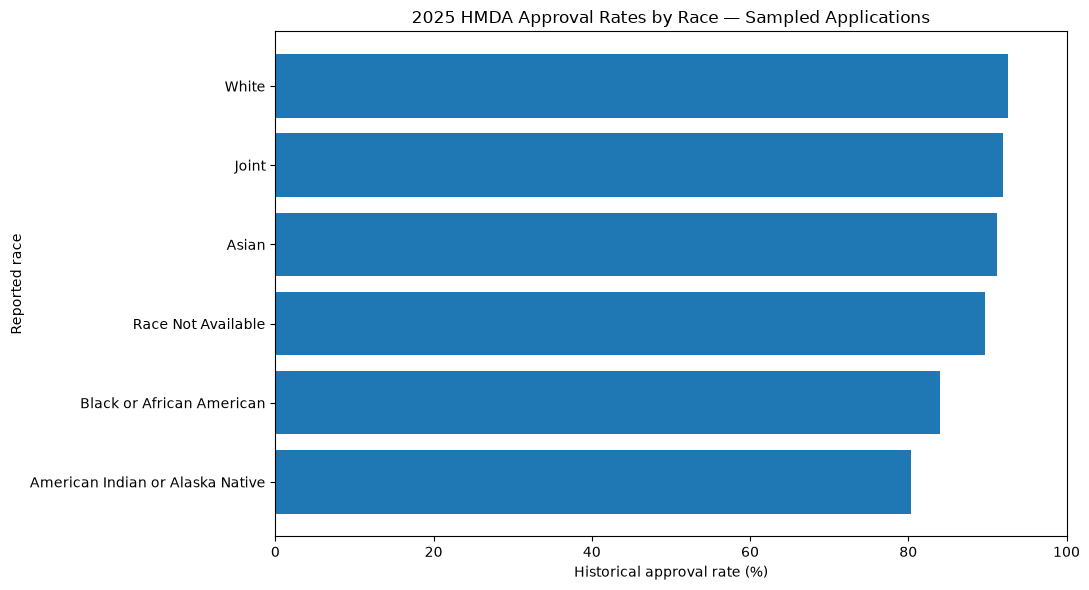

In [27]:
plot_data = race_summary[
    race_summary["applications"] >= 100
].sort_values("approval_rate")

plt.figure(figsize=(11, 6))

plt.barh(
    plot_data["derived_race"],
    plot_data["approval_rate"]
)

plt.xlabel("Historical approval rate (%)")
plt.ylabel("Reported race")
plt.title("2025 HMDA Approval Rates by Race — Sampled Applications")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

In [28]:
from sklearn.metrics import recall_score

audit = test.copy()

audit["predicted_approved"] = (
    model.predict_proba(X_test)[:, 1] >= 0.5
).astype(int)

def denial_recall(group):
    actual_denials = group["approved"] == 0

    if actual_denials.sum() == 0:
        return np.nan

    correctly_identified = (
        actual_denials &
        (group["predicted_approved"] == 0)
    ).sum()

    return correctly_identified / actual_denials.sum()

audit_rows = []

for race, group in audit.groupby(
    "derived_race", dropna=False
):
    audit_rows.append({
        "race": race,
        "applications": len(group),
        "actual_denials": int(
            (group["approved"] == 0).sum()
        ),
        "historical_approval_rate": group["approved"].mean(),
        "predicted_approval_rate": group[
            "predicted_approved"
        ].mean(),
        "denial_recall": denial_recall(group)
    })

fairness_results = pd.DataFrame(audit_rows)

display(
    fairness_results.sort_values(
        "applications", ascending=False
    ).round(3)
)

,race,applications,actual_denials,historical_approval_rate,predicted_approval_rate,denial_recall
8,White,16800,1238,0.926,0.812,0.512
7,Race Not Available,3347,345,0.897,0.781,0.507
3,Black or African American,2072,332,0.840,0.653,0.596
2,Asian,1773,155,0.913,0.854,0.587
5,Joint,712,57,0.920,0.785,0.579
1,American Indian or Alaska Native,173,34,0.803,0.705,0.676
0,2 or more minority races,72,15,0.792,0.653,0.667
6,Native Hawaiian or Other Pacific Islander,48,3,0.938,0.688,0.333
4,Free Form Text Only,3,0,1.000,0.667,NaN


In [29]:
from pathlib import Path

REPORT_DIR = Path("/mnt/data/HMDA_Project/reports")
REPORT_DIR.mkdir(parents=True, exist_ok=True)

feature_importance.to_csv(
    REPORT_DIR / "model_coefficients.csv",
    index=False
)

race_summary.to_csv(
    REPORT_DIR / "approval_rates_by_race_2025.csv",
    index=False
)

fairness_results.to_csv(
    REPORT_DIR / "fairness_audit_2025.csv",
    index=False
)

print("Explainability and fairness reports saved!")

Explainability and fairness reports saved!


,feature,importance,std
3,debt_to_income_ratio,0.1868,0.0033
2,combined_loan_to_value_ratio,0.0147,0.0020
4,loan_type,0.0075,0.0021
5,loan_term,0.0062,0.0010
1,income,-0.0000,0.0000
0,loan_amount,-0.0004,0.0001


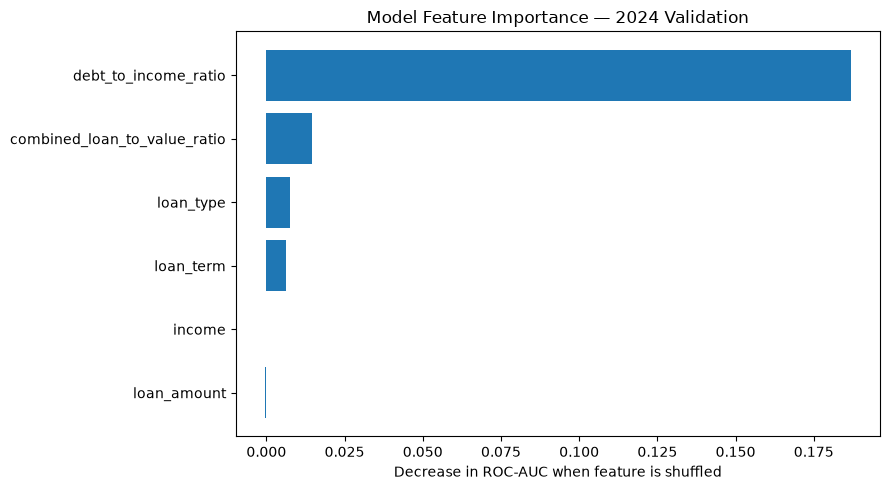

Feature importance report saved!


In [30]:

from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

# Evaluate how much each original feature contributes
# to the model's ranking performance.
importance = permutation_importance(
    model,
    X_val,
    y_val,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=1
)

permutation_df = pd.DataFrame({
    "feature": X_val.columns,
    "importance": importance.importances_mean,
    "std": importance.importances_std
}).sort_values("importance", ascending=False)

display(permutation_df.round(4))

plt.figure(figsize=(9, 5))
plt.barh(
    permutation_df["feature"][::-1],
    permutation_df["importance"][::-1]
)
plt.xlabel("Decrease in ROC-AUC when feature is shuffled")
plt.title("Model Feature Importance — 2024 Validation")
plt.tight_layout()
plt.show()

# Save for the dashboard
permutation_df.to_csv(
    "/mnt/data/HMDA_Project/reports/permutation_importance.csv",
    index=False
)

print("Feature importance report saved!")


In [31]:
from pathlib import Path

base = Path("/mnt/data/HMDA_Project")

for folder in ["models", "reports"]:
    print(f"\n{folder}/")
    for file in sorted((base / folder).glob("*")):
        print(" ", file.name)


models/
  model_metrics.json
  mortgage_approval_model.joblib

reports/
  approval_rates_by_race_2025.csv
  fairness_audit_2025.csv
  model_coefficients.csv
  permutation_importance.csv


In [32]:

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    roc_auc_score,
    balanced_accuracy_score,
    accuracy_score,
    recall_score
)
import numpy as np
import pandas as pd

# Numeric values: impute missing values
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical values: ordinal encode for tree-based model
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1
    ))
])

boost_preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, NUMERIC_FEATURES),
    ("categorical", categorical_pipeline, CATEGORICAL_FEATURES)
])

boost_model = Pipeline([
    ("preprocessor", boost_preprocessor),
    ("classifier", HistGradientBoostingClassifier(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=42
    ))
])

# Train only on 2021–2023
boost_model.fit(X_train, y_train)

print("Gradient boosting model trained!")


Gradient boosting model trained!


In [33]:

lr_probs = model.predict_proba(X_val)[:, 1]
boost_probs = boost_model.predict_proba(X_val)[:, 1]

comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "ROC-AUC": roc_auc_score(y_val, lr_probs),
        "Accuracy at 0.5": accuracy_score(
            y_val, lr_probs >= 0.5
        ),
        "Balanced Accuracy at 0.5": balanced_accuracy_score(
            y_val, lr_probs >= 0.5
        )
    },
    {
        "Model": "Gradient Boosting",
        "ROC-AUC": roc_auc_score(y_val, boost_probs),
        "Accuracy at 0.5": accuracy_score(
            y_val, boost_probs >= 0.5
        ),
        "Balanced Accuracy at 0.5": balanced_accuracy_score(
            y_val, boost_probs >= 0.5
        )
    }
])

display(comparison.round(4))


,Model,ROC-AUC,Accuracy at 0.5,Balanced Accuracy at 0.5
0,Logistic Regression,0.7397,0.8042,0.6899
1,Gradient Boosting,0.7797,0.9301,0.6419


In [34]:

threshold_results = []

for threshold in np.arange(0.50, 1.00, 0.01):
    predictions = (boost_probs >= threshold).astype(int)

    threshold_results.append({
        "threshold": round(float(threshold), 2),
        "accuracy": accuracy_score(y_val, predictions),
        "balanced_accuracy": balanced_accuracy_score(
            y_val, predictions
        ),
        "denial_recall": recall_score(
            y_val, predictions, pos_label=0
        )
    })

threshold_table = pd.DataFrame(threshold_results)

best_row = threshold_table.loc[
    threshold_table["balanced_accuracy"].idxmax()
]

display(
    threshold_table.sort_values(
        "balanced_accuracy", ascending=False
    ).head(10).round(4)
)

print("Best threshold:", best_row["threshold"])
print("Balanced accuracy:", best_row["balanced_accuracy"])
print("Denial recall:", best_row["denial_recall"])


,threshold,accuracy,balanced_accuracy,denial_recall
41,0.91,0.8075,0.7187,0.6101
40,0.90,0.8498,0.7176,0.5558
39,0.89,0.8729,0.7161,0.5243
38,0.88,0.8859,0.7154,0.5068
37,0.87,0.8988,0.7140,0.4880
36,0.86,0.9046,0.7119,0.4761
42,0.92,0.7703,0.7114,0.6394
35,0.85,0.9092,0.7113,0.4691
34,0.84,0.9126,0.7083,0.4582
33,0.83,0.9150,0.7042,0.4464


Best threshold: 0.91
Balanced accuracy: 0.7187242161095219
Denial recall: 0.6100656455142232


In [35]:

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    balanced_accuracy_score,
    recall_score,
    confusion_matrix
)
import pandas as pd

# Evaluate both thresholds on untouched-by-tuning 2025 data
test_probs = boost_model.predict_proba(X_test)[:, 1]

results = []

for threshold in [0.89, 0.91]:
    predictions = (test_probs >= threshold).astype(int)

    results.append({
        "threshold": threshold,
        "roc_auc": roc_auc_score(y_test, test_probs),
        "accuracy": accuracy_score(y_test, predictions),
        "balanced_accuracy": balanced_accuracy_score(y_test, predictions),
        "denial_recall": recall_score(
            y_test, predictions, pos_label=0
        )
    })

display(pd.DataFrame(results).round(4))

print("2024 Boosting ROC-AUC:",
      round(roc_auc_score(y_val, boost_probs), 4))

print("2025 Confusion Matrix at 0.91:")
print(confusion_matrix(
    y_test, (test_probs >= 0.91).astype(int),
    labels=[0, 1]
))


,threshold,roc_auc,accuracy,balanced_accuracy,denial_recall
0,0.89,0.7784,0.8728,0.7089,0.5103
1,0.91,0.7784,0.8073,0.7087,0.5893


2024 Boosting ROC-AUC: 0.7797
2025 Confusion Matrix at 0.91:
[[ 1284   895]
 [ 3923 18898]]


In [36]:

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor_v2 = ColumnTransformer([
    ("numeric", numeric_pipeline, NUMERIC_FEATURES),
    ("categorical", categorical_pipeline, CATEGORICAL_FEATURES)
])

boost_model_v2 = Pipeline([
    ("preprocessor", preprocessor_v2),
    ("classifier", HistGradientBoostingClassifier(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=42
    ))
])

boost_model_v2.fit(X_train, y_train)

print("Improved gradient boosting model trained!")


Improved gradient boosting model trained!


In [37]:

from sklearn.metrics import roc_auc_score
import pandas as pd

comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "2024 ROC-AUC": roc_auc_score(
            y_val, model.predict_proba(X_val)[:, 1]
        )
    },
    {
        "Model": "Gradient Boosting (Ordinal)",
        "2024 ROC-AUC": roc_auc_score(
            y_val, boost_model.predict_proba(X_val)[:, 1]
        )
    },
    {
        "Model": "Gradient Boosting (One-Hot)",
        "2024 ROC-AUC": roc_auc_score(
            y_val, boost_model_v2.predict_proba(X_val)[:, 1]
        )
    }
])

display(comparison.round(4))


,Model,2024 ROC-AUC
0,Logistic Regression,0.7397
1,Gradient Boosting (Ordinal),0.7797
2,Gradient Boosting (One-Hot),0.7794


In [38]:

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    recall_score
)

val_probs_v2 = boost_model_v2.predict_proba(X_val)[:, 1]

threshold_results_v2 = []

for threshold in np.arange(0.50, 1.00, 0.01):
    predictions = (val_probs_v2 >= threshold).astype(int)

    threshold_results_v2.append({
        "threshold": round(float(threshold), 2),
        "accuracy": accuracy_score(y_val, predictions),
        "balanced_accuracy": balanced_accuracy_score(
            y_val, predictions
        ),
        "denial_recall": recall_score(
            y_val, predictions, pos_label=0
        )
    })

threshold_table_v2 = pd.DataFrame(threshold_results_v2)

display(
    threshold_table_v2.sort_values(
        "balanced_accuracy", ascending=False
    ).head(10).round(4)
)

best_threshold_v2 = float(
    threshold_table_v2.loc[
        threshold_table_v2["balanced_accuracy"].idxmax(),
        "threshold"
    ]
)

print("Best 2024 threshold:", best_threshold_v2)


,threshold,accuracy,balanced_accuracy,denial_recall
39,0.89,0.8824,0.7168,0.5142
40,0.90,0.8503,0.7157,0.5510
38,0.88,0.8919,0.7134,0.4950
41,0.91,0.8076,0.7127,0.5965
37,0.87,0.9020,0.7105,0.4761
42,0.92,0.7564,0.7071,0.6468
36,0.86,0.9082,0.7060,0.4586
35,0.85,0.9117,0.7030,0.4477
34,0.84,0.9148,0.7012,0.4398
33,0.83,0.9182,0.7001,0.4333


Best 2024 threshold: 0.89


In [39]:

from sklearn.metrics import confusion_matrix

test_probs_v2 = boost_model_v2.predict_proba(X_test)[:, 1]
test_predictions_v2 = (
    test_probs_v2 >= best_threshold_v2
).astype(int)

final_metrics_v2 = {
    "roc_auc": roc_auc_score(y_test, test_probs_v2),
    "accuracy": accuracy_score(y_test, test_predictions_v2),
    "balanced_accuracy": balanced_accuracy_score(
        y_test, test_predictions_v2
    ),
    "denial_recall": recall_score(
        y_test, test_predictions_v2, pos_label=0
    )
}

print("Selected threshold:", best_threshold_v2)
print(pd.Series(final_metrics_v2).round(4))

print("\nConfusion matrix [denied, approved]:")
print(confusion_matrix(
    y_test, test_predictions_v2, labels=[0, 1]
))


Selected threshold: 0.89
roc_auc              0.7785
accuracy             0.8821
balanced_accuracy    0.7071
denial_recall        0.4952
dtype: float64

Confusion matrix [denied, approved]:
[[ 1079  1100]
 [ 1848 20973]]


In [40]:

import json
import joblib
from pathlib import Path

MODEL_DIR = Path("/mnt/data/HMDA_Project/models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save the full preprocessing + classifier pipeline
joblib.dump(
    boost_model_v2,
    MODEL_DIR / "mortgage_gradient_boosting.joblib"
)

# Save metadata and evaluation metrics
model_metadata = {
    "model": "HistGradientBoostingClassifier",
    "version": "2.0",
    "training_years": [2021, 2022, 2023],
    "validation_year": 2024,
    "test_year": 2025,
    "features": NUMERIC_FEATURES + CATEGORICAL_FEATURES,
    "categorical_encoding": "one_hot",
    "threshold": best_threshold_v2,
    "validation_metrics": {
        "roc_auc": float(
            roc_auc_score(y_val, val_probs_v2)
        )
    },
    "test_metrics": {
        key: float(value)
        for key, value in final_metrics_v2.items()
    }
}

with open(
    MODEL_DIR / "gradient_boosting_metrics.json", "w"
) as f:
    json.dump(model_metadata, f, indent=2)

print("Saved model and metrics successfully!")


Saved model and metrics successfully!


In [41]:

from pathlib import Path
from sklearn.inspection import permutation_importance
import pandas as pd

DATA_DIR = Path("/mnt/data/HMDA_Project")
REPORT_DIR = DATA_DIR / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

# Use 2024 validation data for feature importance
result = permutation_importance(
    boost_model_v2,
    X_val,
    y_val,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=2
)

importance_v2 = pd.DataFrame({
    "feature": X_val.columns,
    "importance_mean": result.importances_mean,
    "importance_std": result.importances_std
}).sort_values("importance_mean", ascending=False)

importance_v2.to_csv(
    REPORT_DIR / "gradient_boosting_permutation_importance.csv",
    index=False
)

display(importance_v2.round(4))


,feature,importance_mean,importance_std
3,debt_to_income_ratio,0.1669,0.0034
2,combined_loan_to_value_ratio,0.0309,0.0020
4,loan_type,0.0305,0.0027
0,loan_amount,0.0191,0.0012
1,income,0.0125,0.0016
5,loan_term,0.0028,0.0004


In [44]:

import pandas as pd
from pathlib import Path

df_2025 = pd.read_parquet(
    "/mnt/data/HMDA_Project/hmda_2025.parquet"
)

print("2025 dataset:", df_2025.shape)
print("Test features:", X_test.shape)
print("Test labels:", len(y_test))

print("Race column exists:",
      "derived_race" in df_2025.columns)


2025 dataset: (25000, 28)
Test features: (25000, 6)
Test labels: 25000
Race column exists: True


In [45]:

import numpy as np

assert len(df_2025) == len(X_test) == len(y_test)

# Confirm feature values match in the same row order
for feature in NUMERIC_FEATURES + CATEGORICAL_FEATURES:
    assert (
        df_2025[feature].reset_index(drop=True)
        .fillna("__MISSING__")
        .astype(str)
        .equals(
            X_test[feature].reset_index(drop=True)
            .fillna("__MISSING__")
            .astype(str)
        )
    ), f"Row alignment failed for {feature}"

print("All rows aligned successfully!")


AssertionError: Row alignment failed for income

In [46]:

import pandas as pd
import numpy as np

raw_income = pd.to_numeric(
    df_2025["income"], errors="coerce"
).reset_index(drop=True)

test_income = pd.to_numeric(
    X_test["income"], errors="coerce"
).reset_index(drop=True)

matches = np.isclose(
    raw_income.to_numpy(),
    test_income.to_numpy(),
    equal_nan=True,
    rtol=1e-8,
    atol=1e-8
)

print("Matching income rows:", matches.sum())
print("Total rows:", len(matches))
print("Match percentage:", round(matches.mean() * 100, 2))

print("\nOriginal data types:")
print(df_2025["income"].dtype, X_test["income"].dtype)

print("\nFirst 10 mismatches:")
display(pd.DataFrame({
    "Raw income": raw_income[~matches].head(10).to_numpy(),
    "X_test income": test_income[~matches].head(10).to_numpy()
}))


Matching income rows: 25000
Total rows: 25000
Match percentage: 100.0

Original data types:
object float64

First 10 mismatches:


,Raw income,X_test income


In [49]:

import pandas as pd
import numpy as np

assert len(df_2025) == len(X_test) == len(y_test)

for feature in NUMERIC_FEATURES + CATEGORICAL_FEATURES:
    raw = df_2025[feature].reset_index(drop=True)
    test = X_test[feature].reset_index(drop=True)

    if feature in NUMERIC_FEATURES:
        a = pd.to_numeric(raw, errors="coerce")
        b = pd.to_numeric(test, errors="coerce")

        matches = np.isclose(
            a.to_numpy(),
            b.to_numpy(),
            equal_nan=True
        )
    else:
        a = raw.fillna("Missing").astype(str).str.strip()
        b = test.fillna("Missing").astype(str).str.strip()

        matches = (a == b).to_numpy()

    print(f"{feature}: {matches.mean():.2%} match")
    assert matches.all(), f"Mismatch in {feature}"

print("\nAll 25,000 rows aligned successfully!")


loan_amount: 100.00% match
income: 100.00% match
combined_loan_to_value_ratio: 100.00% match
debt_to_income_ratio: 100.00% match
loan_type: 100.00% match
loan_term: 100.00% match

All 25,000 rows aligned successfully!


In [50]:
audit_df = df_2025.copy().reset_index(drop=True)

In [51]:

from pathlib import Path

base = Path("/mnt/data/HMDA_Project")

files = [
    base / "models/mortgage_gradient_boosting.joblib",
    base / "models/gradient_boosting_metrics.json",
    base / "reports/gradient_boosting_permutation_importance.csv",
    base / "reports/gradient_boosting_fairness_audit_2025.csv"
]

for file in files:
    print(
        "READY" if file.exists() else "MISSING",
        file.name
    )


READY mortgage_gradient_boosting.joblib
READY gradient_boosting_metrics.json
READY gradient_boosting_permutation_importance.csv
MISSING gradient_boosting_fairness_audit_2025.csv
